In [29]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.titlesize': 14, 'axes.labelsize': 12})

# Estrazione e Data Cleaning
conn = sqlite3.connect('../data/document_analysis.db')

# Estrazione con deduplicazione nativa
query = """
SELECT 
    COALESCE(ea1.canonical_name, t.actor) AS source,
    t.action,
    COALESCE(ea2.canonical_name, t.target) AS target,
    t.timestamp,
    d.category,
    d.paragraph_summary
FROM rdf_triples t
JOIN documents d ON t.doc_id = d.doc_id
LEFT JOIN entity_aliases ea1 ON t.actor = ea1.original_name
LEFT JOIN entity_aliases ea2 ON t.target = ea2.original_name
"""
df = pd.read_sql_query(query, conn)
conn.close()

# Pulizia: Rimuoviamo righe senza Source o Target
df_clean = df.dropna(subset=['source', 'target']).copy()

# Estrazione dell'anno a 4 cifre dal timestamp
df_clean['year'] = df_clean['timestamp'].astype(str).str.extract(r'\b(19\d{2}|20\d{2})\b').astype(float)

Totale Relazioni Eratte (Edges): 107,021
Relazioni valide per il Network (Source & Target presenti): 107,021

Analisi Valori Nulli (Missing Values):
           Valori Nulli  Percentuale (%)
timestamp         45541        42.553331
year              45966        42.950449


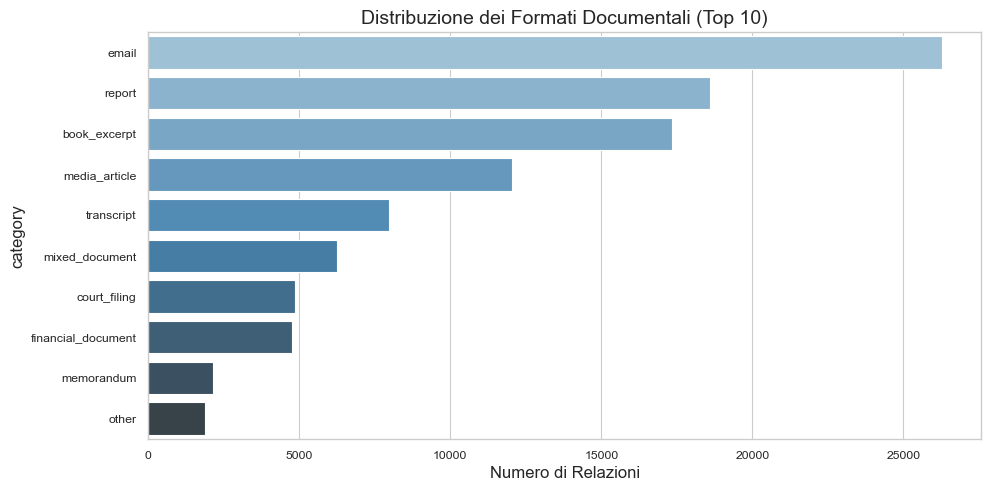

In [ ]:
# Macro-Analisi e Visualizzazioni
print(f"Totale Relazioni Eratte (Edges): {len(df):,}")
print(f"Relazioni valide per il Network (Source & Target presenti): {len(df_clean):,}")

# Missing Values Analysis
print("\nAnalisi Valori Nulli (Missing Values):")
missing_stats = df_clean.isnull().sum()
missing_pct = (missing_stats / len(df_clean)) * 100
missing_df = pd.DataFrame({'Valori Nulli': missing_stats, 'Percentuale (%)': missing_pct})
print(missing_df[missing_df['Percentuale (%)'] > 0].to_string())

# Tipi di documenti più frequenti
plt.figure(figsize=(10, 5))
top_cats = df_clean['category'].value_counts().head(10)
sns.barplot(x=top_cats.values, y=top_cats.index, hue=top_cats.index, palette='Blues_d', legend=False)
plt.title("Distribuzione dei Formati dei Documenti (Top 10)")
plt.xlabel("Numero di Relazioni")
plt.tight_layout()
plt.show()

Nodi unici totali nel network: 55,879


/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_32183/94775483.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_nodes.values, y=top_nodes.index, palette=colors)


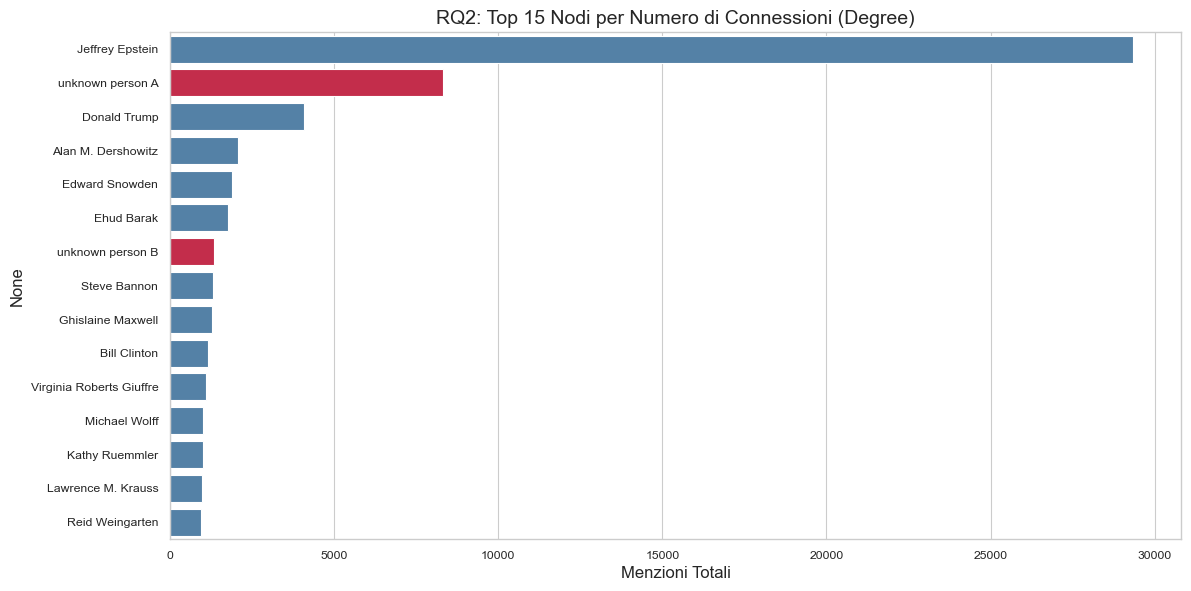

NOTE RQ2: La rete possiede decine di migliaia di nodi, ma il nodo 'unknown person A' domina in modo anomalo la topologia (evidenziato in rosso).
Questa non è un'anomalia da rimuovere, ma la prova strutturale dell'esistenza di forti meccanismi di 'secrecy'. L'uso della Betweenness Centrality calcolerà esattamente il loro potere di Brokerage.


In [31]:
# Calcoliamo il Grado (Degree) di ogni nodo combinando source e target
all_nodes = pd.concat([df_clean['source'], df_clean['target']])
node_degrees = all_nodes.value_counts()

print(f"Nodi unici totali nel network: {len(node_degrees):,}")

plt.figure(figsize=(12, 6))
top_nodes = node_degrees.head(15)
# Evidenziamo gli 'Unknown' in rosso per la RQ2
colors = ['crimson' if 'unknown' in str(idx).lower() else 'steelblue' for idx in top_nodes.index]
sns.barplot(x=top_nodes.values, y=top_nodes.index, palette=colors)
plt.title("RQ2: Top 15 Nodi per Numero di Connessioni (Degree)")
plt.xlabel("Menzioni Totali")
plt.tight_layout()
plt.show()

print("NOTE RQ2: La rete possiede decine di migliaia di nodi, ma il nodo 'unknown person A' domina in modo anomalo la topologia (evidenziato in rosso).")
print("Questa non è un'anomalia da rimuovere, ma la prova strutturale dell'esistenza di forti meccanismi di 'secrecy'. L'uso della Betweenness Centrality calcolerà esattamente il loro potere di Brokerage.")

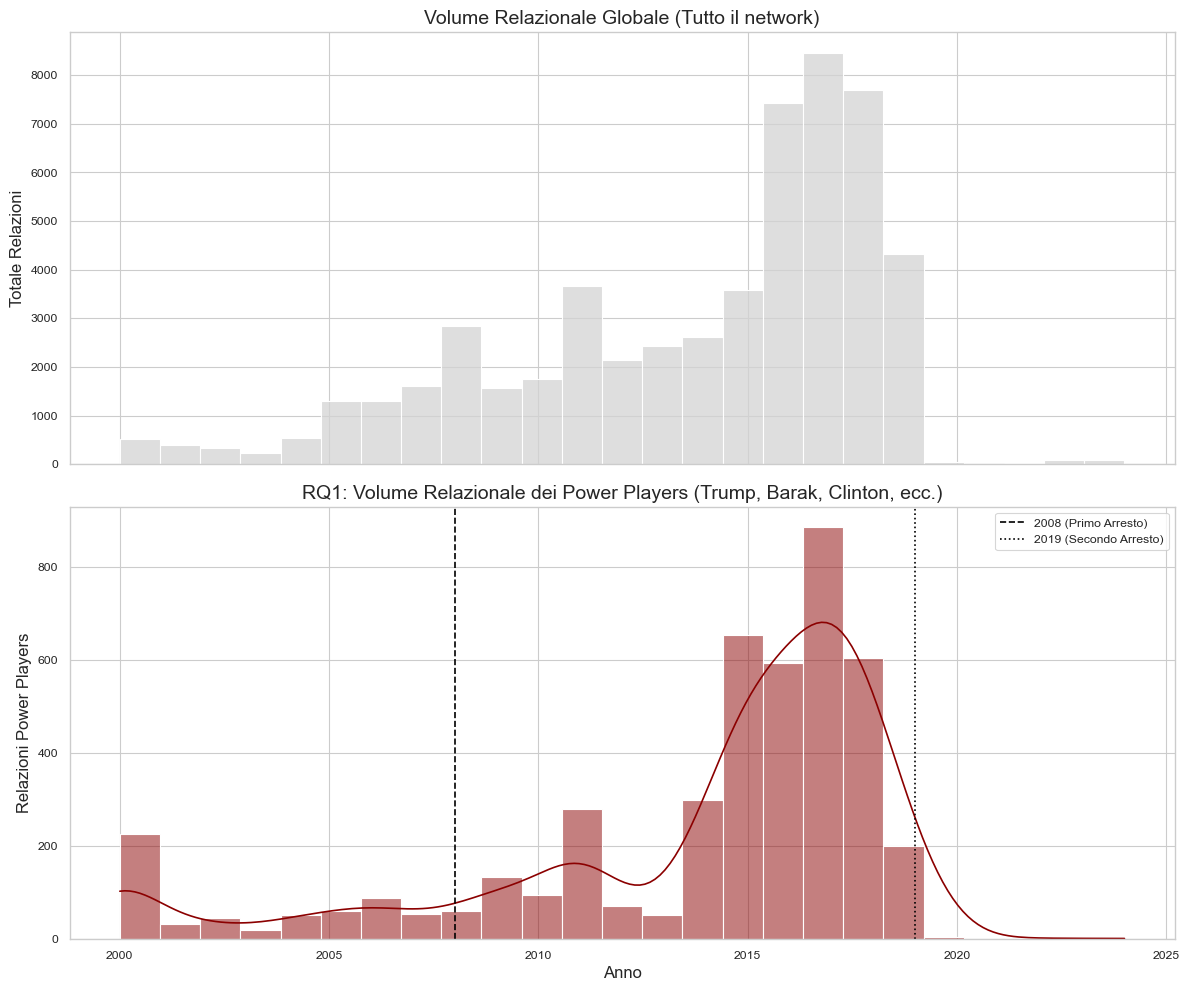

🎯 NOTE RQ1: Mentre il network globale ha la sua rumorosità, l'attività che coinvolge le figure di potere esplode in modo sospetto a ridosso del 2008 e del 2019.
L'applicazione di RoBERTa ci svelerà se questo iper-attivismo corrisponde a una 'deriva negativa' del sentiment (prese di distanza, battaglie legali).


In [ ]:
df_years = df_clean[(df_clean['year'] >= 2000) & (df_clean['year'] <= 2024)].copy()

# Selezioniamo un sottogruppo di Power Players per la RQ1
power_players = ['Donald Trump', 'Bill Clinton', 'Ehud Barak', 'Alan M. Dershowitz', 'Ghislaine Maxwell']
df_power = df_years[(df_years['source'].isin(power_players)) | (df_years['target'].isin(power_players))]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot Globale
sns.histplot(data=df_years, x='year', bins=25, color='lightgray', ax=ax1)
ax1.set_title("Volume Relazionale Globale (Tutto il network)")
ax1.set_ylabel("Totale Relazioni")

# Plot Power Players (RQ1)
sns.histplot(data=df_power, x='year', bins=25, color='darkred', ax=ax2, kde=True)
ax2.set_title("RQ1: Volume Relazionale dei Power Players")
ax2.set_ylabel("Relazioni Power Players")
ax2.axvline(x=2008, color='black', linestyle='--', label='2008 (Primo Arresto)')
ax2.axvline(x=2019, color='black', linestyle=':', label='2019 (Secondo Arresto)')
ax2.legend()

plt.xlabel("Anno")
plt.tight_layout()
plt.show()

print("NOTE RQ1: Mentre il network globale ha la sua rumorosità, l'attività che coinvolge le figure di potere esplode in modo sospetto dopo il 2008.")
print("L'applicazione di RoBERTa ci svelerà se questo iper-attivismo corrisponde a una 'deriva negativa' del sentiment (prese di distanza, battaglie legali).")

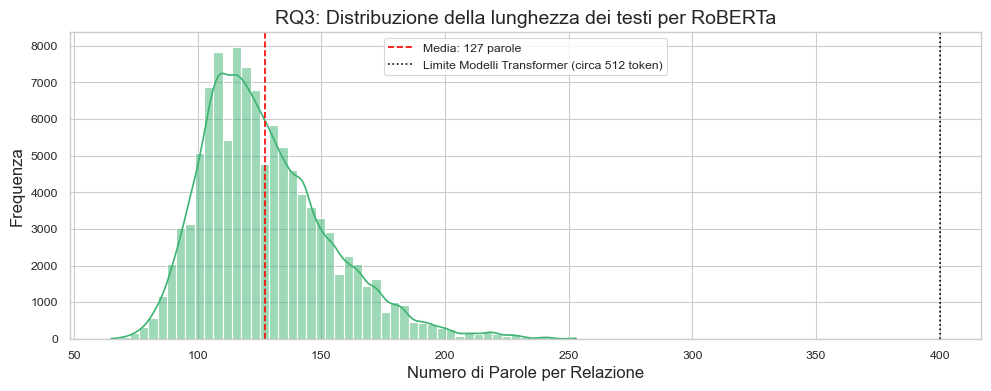

NOTE RQ3: Copertura Testuale del 100.0% sull'intero dataset.
La stragrande maggioranza dei testi si attesta sotto la soglia critica dei Transformer. Nessun troncamento semantico avverrà.
Questo garantisce che il peso di Sentiment che assegneremo agli archi del Grafo sarà altamente accurato, permettendoci di ridefinire la Centralità in base alla polarità.


In [33]:
df_text = df_clean.dropna(subset=['paragraph_summary']).copy()
# Calcolo della lunghezza esatta del testo
df_text['word_count'] = df_text['paragraph_summary'].apply(lambda x: len(str(x).split()))

coverage = (len(df_text) / len(df_clean)) * 100
mean_length = df_text['word_count'].mean()

plt.figure(figsize=(10, 4))
sns.histplot(data=df_text, x='word_count', bins=50, kde=True, color='mediumseagreen')
plt.axvline(x=mean_length, color='red', linestyle='--', label=f'Media: {mean_length:.0f} parole')
plt.axvline(x=400, color='black', linestyle=':', label='Limite Modelli Transformer (circa 512 token)')
plt.title("RQ3: Distribuzione della lunghezza dei testi per RoBERTa")
plt.xlabel("Numero di Parole per Relazione")
plt.ylabel("Frequenza")
plt.legend()
plt.tight_layout()
plt.show()

print(f"NOTE RQ3: Copertura Testuale del {coverage:.1f}% sull'intero dataset.")
print(f"La stragrande maggioranza dei testi si attesta sotto la soglia critica dei Transformer. Nessun troncamento semantico avverrà.")
print("Questo garantisce che il peso di Sentiment che assegneremo agli archi del Grafo sarà altamente accurato, permettendoci di ridefinire la Centralità in base alla polarità.")